# FarmTech Solutions – Fase 6 | Entrega 2: CNN treinada do zero
**Classes:** Banana (A) x Garrafa PET (B)

Objetivo: treinar uma CNN do zero para classificar a imagem inteira (sem bounding boxes) usando **o mesmo dataset** da Entrega 1 (train/val/test, 32/4/4 por classe), e coletar métricas para a comparação com a YOLO customizada e a YOLO padrão: facilidade de uso, precisão, tempo de treino e tempo de inferência.

**Autor:** Matheus Fontes — RM 570457. **Grupo:** 21. **Tutora:** Nicolly Candida.

A comparação das três abordagens está no [notebook da Entrega 2](https://github.com/Grupo-IA-FIAP-EMLL-2026-2/fase6-cap1-farmtech/blob/main/EltonModestoDeSouzaDias_rm572530_pbl_fase6.ipynb). Os códigos e as saídas salvas desta contribuição foram preservados na integração.


## 1. Configuração e montagem do Drive

In [1]:
import os, time, random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Colab: monta o Drive. Local: usa a copia baixada do dataset
try:
    from google.colab import drive
    drive.mount('/content/drive')
    EM_COLAB = True
except ImportError:
    EM_COLAB = False

# Dataset da Entrega 1 (formato YOLO, no Drive; usado somente para LEITURA)
YOLO_DIR = ('/content/drive/MyDrive/FIAP_fase6_grupo21/dataset_yolo/organizado' if EM_COLAB
            else 'dataset_yolo-20261012T153902Z-1-001/dataset_yolo/organizado')
# Copia local organizada por classe, gerada na secao 1.1
DATASET_DIR = '/content/cnn_dataset' if EM_COLAB else 'cnn_dataset'
IMG_SIZE = (128, 128)
BATCH_SIZE = 8
EPOCHS = 30
SEED = 42

random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

### 1.1 Conversao do dataset YOLO para pastas por classe
A CNN classifica a imagem inteira, entao precisa de `split/classe/imagem.jpg`. No dataset da Entrega 1 as imagens ficam em `images/{train,val,test}` e a classe esta no primeiro numero de cada linha do `.txt` em `labels/`. Esta celula le os labels (sem alterar nada no Drive) e copia as imagens para `/content/cnn_dataset`, mantendo a **mesma divisao** treino/validacao/teste da YOLO, o que torna a comparacao justa.


In [2]:
import shutil, yaml
from collections import Counter

# Nomes das classes vindos do data.yaml (0 = banana, 1 = garrafa_pet)
with open(f'{YOLO_DIR}/data.yaml') as f:
    names = yaml.safe_load(f)['names']

shutil.rmtree(DATASET_DIR, ignore_errors=True)  # recomeca limpo; so afeta a copia local
contagem = Counter()
for split in ['train', 'val', 'test']:
    for img in sorted(os.listdir(f'{YOLO_DIR}/images/{split}')):
        stem, ext = os.path.splitext(img)
        if ext.lower() not in ('.jpg', '.jpeg', '.png'):
            continue
        lbl = f'{YOLO_DIR}/labels/{split}/{stem}.txt'
        with open(lbl) as f:
            classes = {int(l.split()[0]) for l in f if l.strip()}
        assert len(classes) == 1, f'{img}: imagem com mais de uma classe {classes}'  # 1 classe por imagem
        nome = names[classes.pop()]
        os.makedirs(f'{DATASET_DIR}/{split}/{nome}', exist_ok=True)
        shutil.copy(f'{YOLO_DIR}/images/{split}/{img}', f'{DATASET_DIR}/{split}/{nome}/{img}')
        contagem[(split, nome)] += 1

# Confere a divisao esperada (32/4/4 por classe)
for k in sorted(contagem): print(k, contagem[k])


('test', 'banana') 4
('test', 'garrafa_pet') 4
('train', 'banana') 32
('train', 'garrafa_pet') 32
('val', 'banana') 4
('val', 'garrafa_pet') 4


## 2. Carregamento dos dados
Usamos `image_dataset_from_directory`: o nome de cada subpasta vira o rótulo da classe. Os conjuntos de validação e teste **não** são embaralhados, para a matriz de confusão ficar alinhada.

In [3]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    f'{DATASET_DIR}/train', image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=True, seed=SEED)
val_ds = tf.keras.utils.image_dataset_from_directory(
    f'{DATASET_DIR}/val', image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False)
test_ds = tf.keras.utils.image_dataset_from_directory(
    f'{DATASET_DIR}/test', image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False)

class_names = train_ds.class_names
print('Classes:', class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 64 files belonging to 2 classes.


Found 8 files belonging to 2 classes.


Found 8 files belonging to 2 classes.


Classes: ['banana', 'garrafa_pet']


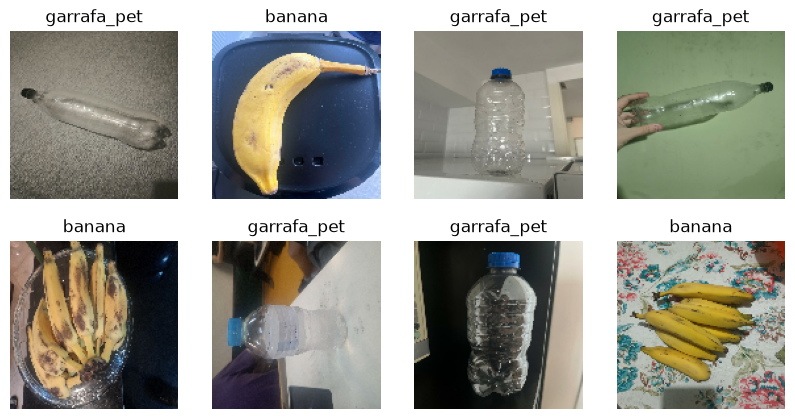

In [4]:
# Amostra de imagens de treino
plt.figure(figsize=(10, 5))
for images, labels in train_ds.take(1):
    for i in range(min(8, len(images))):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(class_names[labels[i]]); plt.axis('off')
plt.show()

## 3. Arquitetura da CNN
Com poucas imagens (64 de treino), a rede é pequena e usa **data augmentation** e **Dropout** para reduzir o overfitting. Saída com 1 neurônio sigmoid (classificação binária).

**Escolhas:** imagens redimensionadas para 128x128 (as fotos originais tem varios MB; 128 px basta para separar um objeto alongado amarelo de uma garrafa e mantem o treino rapido). Tres blocos Conv+MaxPooling com 16, 32 e 64 filtros: poucos parametros para um dataset de 64 imagens, com campo receptivo crescente. `Dropout(0.5)` e *data augmentation* (flip, rotacao e zoom) combatem o overfitting. `Adam` e `binary_crossentropy` sao o padrao para saida sigmoide binaria. Batch de 8 e 30 epocas. Os modelos usam arquiteturas e condições distintas; igualar épocas, sozinho, não torna a comparação de tempos controlada.


In [5]:
data_augmentation = models.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

model = models.Sequential([
    layers.Input(shape=IMG_SIZE + (3,)),
    data_augmentation,
    layers.Rescaling(1./255),
    layers.Conv2D(16, 3, activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'), layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid'),
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       802,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 826,529 (3.15 MB)

 Trainable params: 826,529 (3.15 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Treinamento (com medição do tempo)

In [6]:
t0 = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS)
train_time = time.time() - t0
print(f'Tempo de treinamento: {train_time:.1f} s')

Epoch 1/30


C:\fase6-cap1-farmtech\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.3750 - loss: 0.7173

4/8 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.3750 - loss: 0.8286

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.4531 - loss: 0.7434

...

1/8 ━━━━━━━━━━━━━━━━━━━━ 1s 212ms/step - accuracy: 1.0000 - loss: 0.0024

3/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 1.0000 - loss: 0.0461 

6/8 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 1.0000 - loss: 0.0307

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.9844 - loss: 0.0394 - val_accuracy: 1.0000 - val_loss: 0.0149


Tempo de treinamento: 15.6 s


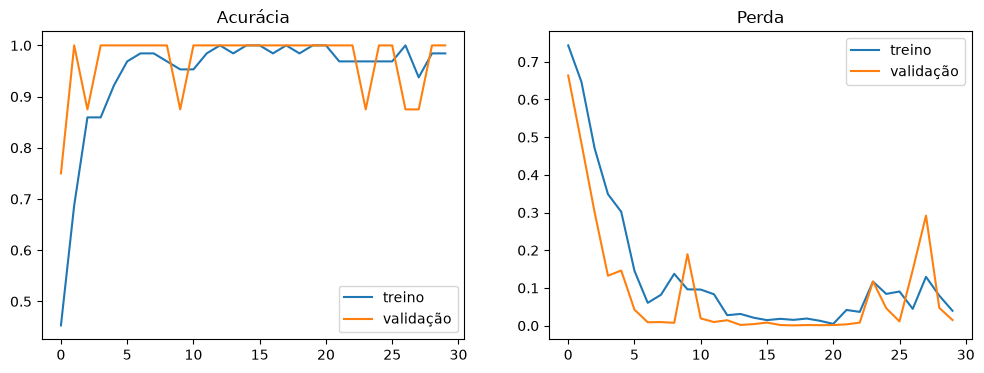

In [7]:
# Curvas de acurácia e perda
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history['accuracy'], label='treino'); ax[0].plot(history.history['val_accuracy'], label='validação')
ax[0].set_title('Acurácia'); ax[0].legend()
ax[1].plot(history.history['loss'], label='treino'); ax[1].plot(history.history['val_loss'], label='validação')
ax[1].set_title('Perda'); ax[1].legend()
plt.show()

## 5. Avaliação no conjunto de teste

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 1.0000 - loss: 0.0022

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 1.0000 - loss: 0.0022


Teste -> acurácia: 1.000 | perda: 0.002
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step


              precision    recall  f1-score   support

      banana       1.00      1.00      1.00         4
 garrafa_pet       1.00      1.00      1.00         4

    accuracy                           1.00         8
   macro avg       1.00      1.00      1.00         8
weighted avg       1.00      1.00      1.00         8



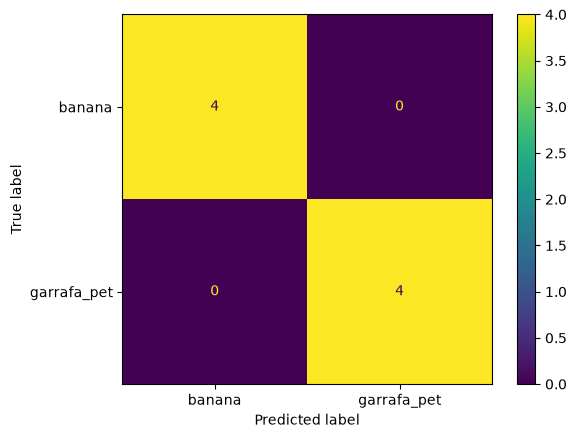

In [8]:
test_loss, test_acc = model.evaluate(test_ds)
print(f'Teste -> acurácia: {test_acc:.3f} | perda: {test_loss:.3f}')

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = model.predict(test_ds).ravel()
y_pred = (y_prob > 0.5).astype(int)

print(classification_report(y_true, y_pred, target_names=class_names))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=class_names).plot()
plt.show()

## 6. Tempo de inferência

In [9]:
# Média por imagem sobre o conjunto de teste (uma primeira chamada de aquecimento fica de fora)
model.predict(test_ds, verbose=0)
t0 = time.time()
model.predict(test_ds, verbose=0)
infer_time = (time.time() - t0) / len(y_true)
print(f'Tempo médio de inferência: {infer_time*1000:.1f} ms/imagem')

Tempo médio de inferência: 9.4 ms/imagem


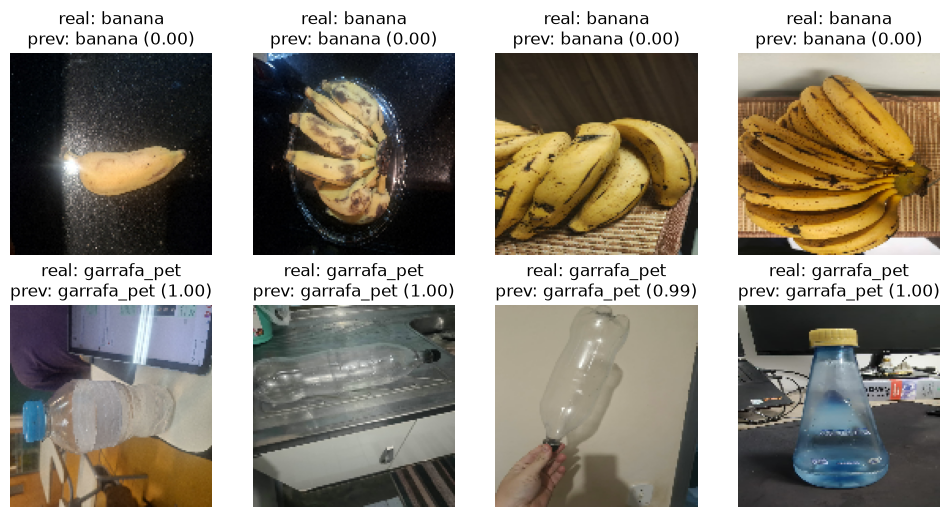

In [10]:
# Imagens de teste classificadas pelo modelo
plt.figure(figsize=(12, 6))
i = 0
for images, labels in test_ds:
    for img, lab in zip(images, labels):
        if i >= 8: break
        p = model.predict(img[None], verbose=0)[0][0]
        plt.subplot(2, 4, i + 1)
        plt.imshow(img.numpy().astype('uint8'))
        plt.title(f'real: {class_names[lab]}\nprev: {class_names[int(p>0.5)]} ({p:.2f})'); plt.axis('off')
        i += 1
plt.show()

## 7. Resumo para a comparacao entre abordagens
| Criterio | Valor |
|---|---|
| Acuracia no teste | 1,00 (8/8 imagens; precisao, recall e F1 = 1,00 nas duas classes) |
| Tempo de treinamento | 15,6 s (30 epocas, CPU local, nao Colab) |
| Tempo de inferencia por imagem | 9,4 ms (media sobre o teste, CPU local) |
| Facilidade de uso/integracao | Alta para classificar a imagem inteira: poucas linhas em Keras, sem rotulacao de caixas e com TensorFlow e bibliotecas de apoio. Limitação: informa a classe, não a localização, e assume uma classe alvo por foto; pode haver vários objetos dessa classe. |


O resultado de 8/8 corresponde a um teste pequeno e não demonstra desempenho universal. A inferência foi medida após aquecimento, com predict sobre oito imagens em lote, dividindo o tempo pelo número de fotos. Não equivale ao tempo isolado de cálculo da YOLO na GPU. Uma foto pode conter várias bananas, embora a CNN produza apenas uma classe para a foto inteira.
